# Final Project: SUPPORT2

**Dataset:** SUPPORT2 (Study to Understand Prognoses and Preferences for Outcomes and Risks of Treatments)

**Source:** UCI Machine Learning Repository

https://archive.ics.uci.edu/dataset/880/support2

**Proposed Prediction Problem:** Can demographic, clinical, physiologic, and disease-related characteristics be used to predict in-hospital mortality among seriously ill hospitalized patients?

**Target Variable:** `hospdead`
- `0` = Patient did not die in the hospital
- `1` = Patient died in the hospital

## 0. Data Importing

The workflow supports two data-input pathways. By default, the SUPPORT2 dataset is retrieved directly from the UCI Machine Learning Repository to provide a reproducible version of the analysis. Alternatively, a user may set `DATA_SOURCE = "upload"` to upload a compatible CSV file from the local environment when running the notebook in Google Colab.

The upload pathway includes basic input validation to confirm that a file was provided, that the uploaded file is a CSV, and that the required target variable (`hospdead`) is present. Additional dataset-level validation is performed in the automated validation section below.

The default `DATA_SOURCE = "uci"` setting allows the complete notebook to execute without requiring manual file selection during a reproducibility check.

In [1]:
# Install the UCI repository package
!pip install ucimlrepo -q

import pandas as pd
from ucimlrepo import fetch_ucirepo

# DATA SOURCE CONFIGURATION
#   "uci"    -> automatically load SUPPORT2 from UCI
#   "upload" -> upload a compatible CSV from the local computer

DATA_SOURCE = "uci"
TARGET = "hospdead"

if DATA_SOURCE == "uci":
    # Load SUPPORT2 directly from the UCI Machine Learning Repository
    support2 = fetch_ucirepo(id=880)

    X_source = support2.data.features.copy()
    y_source = support2.data.targets.copy()

    df = X_source.copy()
    df[TARGET] = y_source[TARGET]

    print("Dataset loaded successfully from the UCI Machine Learning Repository.")

elif DATA_SOURCE == "upload":
    # Allow a user to upload a compatible CSV in Google Colab
    from google.colab import files

    uploaded = files.upload()

    if not uploaded:
        raise ValueError("No file was uploaded.")

    filename = next(iter(uploaded))

    if not filename.lower().endswith(".csv"):
        raise ValueError("Unsupported file type. Please upload a CSV file.")
    try:
        df = pd.read_csv(filename)
    except Exception as error:
        raise ValueError(f"The uploaded CSV could not be read: {error}")

    if TARGET not in df.columns:
        raise ValueError(f"The uploaded dataset must contain the target column '{TARGET}'.")

    print(f"Dataset uploaded successfully: {filename}")

else:
    raise ValueError("DATA_SOURCE must be either 'uci' or 'upload'.")

print(f"Dataset shape: {df.shape}")
print(f"Target variable: {TARGET}")

Dataset loaded successfully from the UCI Machine Learning Repository.
Dataset shape: (9105, 43)
Target variable: hospdead


## 1. Analysis Configuration

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    brier_score_loss,
    roc_curve)

In [3]:
# Reproducibility
RANDOM_STATE = 101
TEST_SIZE = 0.20

print("Analysis configuration loaded.")
print(f"Random state: {RANDOM_STATE}")
print(f"Test size: {TEST_SIZE:.0%}")
print(f"Target variable: {TARGET}")

Analysis configuration loaded.
Random state: 101
Test size: 20%
Target variable: hospdead


## 2. Automated Data Validation

Before preprocessing, the dataset is programmatically validated to confirm that its structure and target variable are appropriate for the planned binary classification analysis. These checks provide an early warning if the dataset structure changes or unexpected values are introduced.

The validation procedure examines dataset dimensions, duplicate observations, target completeness and class values, predictor missingness, and variables with constant values.

In [4]:
def validate_dataset(data, target):
    """Perform basic validation checks before preprocessing and modeling."""

    print("=" * 60)
    print("DATA VALIDATION REPORT")
    print("=" * 60)

    # Dataset dimensions
    print(f"\nObservations: {data.shape[0]:,}")
    print(f"Total columns: {data.shape[1]}")
    print(f"Predictors: {data.shape[1] - 1}")

    # Target validation
    if target not in data.columns:
        raise ValueError(f"Target variable '{target}' was not found.")

    target_missing = data[target].isna().sum()
    target_values = sorted(data[target].dropna().unique().tolist())

    print("\nTARGET VALIDATION")
    print(f"Missing target values: {target_missing}")
    print(f"Observed target values: {target_values}")

    if target_missing > 0:
        raise ValueError("Target contains missing values.")

    if set(target_values) != {0, 1}:
        raise ValueError(f"Expected a binary target coded as 0/1, but found {target_values}.")

    print("Binary target check: PASSED")

    # Duplicate rows
    duplicate_count = data.duplicated().sum()

    print("\nDUPLICATE CHECK")
    print(f"Duplicate rows: {duplicate_count:,}")

    # Missing predictor values
    predictor_data = data.drop(columns=target)
    missing_predictors = predictor_data.isna().sum()
    variables_with_missingness = (missing_predictors > 0).sum()

    print("\nMISSINGNESS CHECK")
    print(f"Predictors containing missing values: "
    f"{variables_with_missingness} / {predictor_data.shape[1]}")

    # Constant predictors
    constant_columns = [col for col in predictor_data.columns
                        if predictor_data[col].nunique(dropna=True) <= 1]

    print("\nCONSTANT PREDICTOR CHECK")
    print(f"Constant predictors: {len(constant_columns)}")

    if constant_columns:
        print("Columns:", constant_columns)
    else:
        print("No constant predictors detected.")

    print("\n" + "=" * 60)
    print("VALIDATION COMPLETE")
    print("=" * 60)

    return {"observations": data.shape[0],
            "predictors": predictor_data.shape[1],
            "duplicate_rows": duplicate_count,
            "missing_target_values": target_missing,
            "variables_with_missingness": variables_with_missingness,
            "constant_predictors": constant_columns}

validation_results = validate_dataset(df, TARGET)

DATA VALIDATION REPORT

Observations: 9,105
Total columns: 43
Predictors: 42

TARGET VALIDATION
Missing target values: 0
Observed target values: [0, 1]
Binary target check: PASSED

DUPLICATE CHECK
Duplicate rows: 0

MISSINGNESS CHECK
Predictors containing missing values: 32 / 42

CONSTANT PREDICTOR CHECK
Constant predictors: 0
No constant predictors detected.

VALIDATION COMPLETE


### Validation Summary

The automated validation confirmed that the working dataset contains 9,105 observations and 42 predictor variables. The binary target variable, `hospdead`, contains no missing values and is correctly coded as 0 and 1. No duplicate observations or constant predictors were identified.

Missing data remain the primary data-quality concern, with 32 of the 42 predictors containing at least one missing value. These findings support proceeding with the planned missing-data preprocessing strategy while retaining all observations prior to the train-test split.

## 3. Descriptive Statistics

In [5]:
# Generate descriptive statistics for numerical variables
numerical_cols = df.select_dtypes(include=["int64", "float64"]).columns

# Exclude the target variable from predictor summaries
numerical_predictors = numerical_cols.drop("hospdead")

df[numerical_predictors].describe().T

,count,mean,std,min,25%,50%,75%,max
age,9105.0,62.650823,15.593710,18.041990,52.797000,64.856990,73.998960,1.018480e+02
num.co,9105.0,1.868644,1.344409,0.000000,1.000000,2.000000,3.000000,9.000000e+00
edu,7471.0,11.747691,3.447743,0.000000,10.000000,12.000000,14.000000,3.100000e+01
scoma,9104.0,12.058546,24.636694,0.000000,0.000000,0.000000,9.000000,1.000000e+02
charges,8933.0,59995.787811,102648.778198,1169.000000,9740.000000,25024.000000,64598.000000,1.435423e+06
totcst,8217.0,30825.867768,45780.820986,0.000000,5929.566400,14452.734400,36087.937500,6.332120e+05
totmcst,5630.0,28828.877838,43604.261932,-102.719970,5177.404300,13223.500000,34223.601600,7.106820e+05
avtisst,9023.0,22.610928,13.233248,1.000000,12.000000,19.500000,31.666656,8.300000e+01
sps,9104.0,25.525872,9.899377,0.199982,19.000000,23.898438,30.199219,9.918750e+01
aps,9104.0,37.597979,19.903852,0.000000,23.000000,34.000000,49.000000,1.430000e+02


The descriptive statistics show substantial variation across the clinical and demographic predictors. Patients had a mean age of approximately 62.7 years, with ages ranging from 18 to approximately 102 years. Patients had a median of two comorbidities. Several clinical measures, including hospital charges, costs, bilirubin, creatinine, glucose, blood urea nitrogen, and urine output, show wide ranges and potential skewness or extreme values.

The differing counts across variables also confirm that missing data are present. For example, age and number of comorbidities contain complete observations, while variables such as glucose, urine output, and ADL measures contain substantially fewer observations. Missingness and potentially unusual values will require further investigation during the data quality assessment.

In [6]:
# Identify categorical predictors
categorical_predictors = df.select_dtypes(include="object").columns

# Display category counts for each categorical predictor
for col in categorical_predictors:
    print(f"\n{col}")
    print(df[col].value_counts(dropna=False))


sex
sex
male      5125
female    3980
Name: count, dtype: int64

dzgroup
dzgroup
ARF/MOSF w/Sepsis    3515
CHF                  1387
COPD                  967
Lung Cancer           908
MOSF w/Malig          712
Coma                  596
Colon Cancer          512
Cirrhosis             508
Name: count, dtype: int64

dzclass
dzclass
ARF/MOSF              4227
COPD/CHF/Cirrhosis    2862
Cancer                1420
Coma                   596
Name: count, dtype: int64

income
income
NaN           2982
under $11k    2855
$11-$25k      1527
$25-$50k      1057
>$50k          684
Name: count, dtype: int64

race
race
white       7191
black       1391
hispanic     290
other        112
asian         79
NaN           42
Name: count, dtype: int64

ca
ca
no            5995
metastatic    1858
yes           1252
Name: count, dtype: int64

dnr
dnr
no dnr             5880
dnr after sadm     2956
dnr before sadm     239
NaN                  30
Name: count, dtype: int64


The categorical predictors represent patient demographic, diagnostic, and clinical characteristics. The sample included more male patients (5,125) than female patients (3,980). ARF/MOSF was the most common disease class, and ARF/MOSF with sepsis was the most common specific disease group. Most patients did not have cancer, while patients with cancer were classified as either non-metastatic or metastatic.

The categorical summaries also show differences in group sizes and missingness. For example, income contains 2,982 missing observations, while race contains 42 missing observations and DNR status contains 30. These patterns will be examined further during the data quality assessment and considered during preprocessing.

## 4. Exploratory Data Analysis

#### 4.1 In-Hospital Mortality Distribution

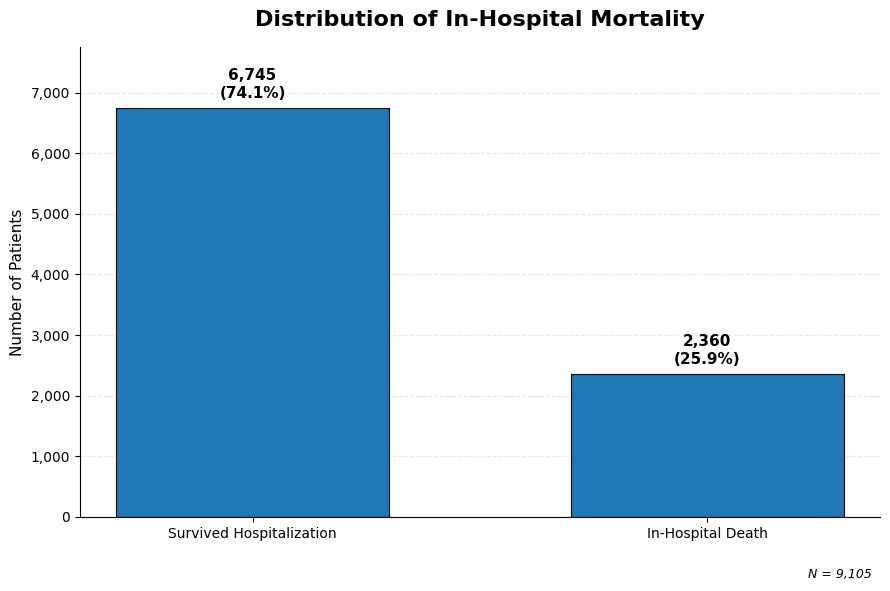

In [7]:
# Prepare mortality counts and percentages
mortality_counts = (
    df["hospdead"]
    .value_counts()
    .sort_index())

mortality_percent = mortality_counts / mortality_counts.sum() * 100

mortality_plot = pd.DataFrame({
    "Outcome": ["Survived Hospitalization", "In-Hospital Death"],
    "Count": mortality_counts.values,
    "Percent": mortality_percent.values})

# Create figure
fig, ax = plt.subplots(figsize=(9, 6))

bars = ax.bar(
    mortality_plot["Outcome"],
    mortality_plot["Count"],
    width=0.6,
    edgecolor="black",
    linewidth=0.8)

# Add count and percentage labels above each bar
for bar, count, pct in zip(
    bars,
    mortality_plot["Count"],
    mortality_plot["Percent"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 120,
        f"{count:,}\n({pct:.1f}%)",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold")

# Titles and labels
ax.set_title(
    "Distribution of In-Hospital Mortality",
    fontsize=16,
    fontweight="bold",
    pad=15)

ax.set_xlabel("")
ax.set_ylabel("Number of Patients", fontsize=11)

# Format y-axis with commas
ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"{int(x):,}"))

# Give labels room above bars
ax.set_ylim(0, mortality_plot["Count"].max() * 1.15)

# Clean up chart appearance
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.3)

ax.set_axisbelow(True)

# Add sample-size note
ax.text(
    0.99,
    -0.13,
    f"N = {len(df):,}",
    transform=ax.transAxes,
    ha="right",
    fontsize=9,
    style="italic")

plt.tight_layout()
plt.show()

The visualization demonstrates an imbalance in the binary outcome, with 74.1% of patients surviving hospitalization and 25.9% experiencing in-hospital mortality. Although both outcome classes contain a substantial number of observations, the unequal class distribution suggests that model performance should not be evaluated using accuracy alone. Metrics that account for classification performance across the outcome classes will be considered during model evaluation.

#### 4.2 In-Hospital Mortality Rate by Disease Class

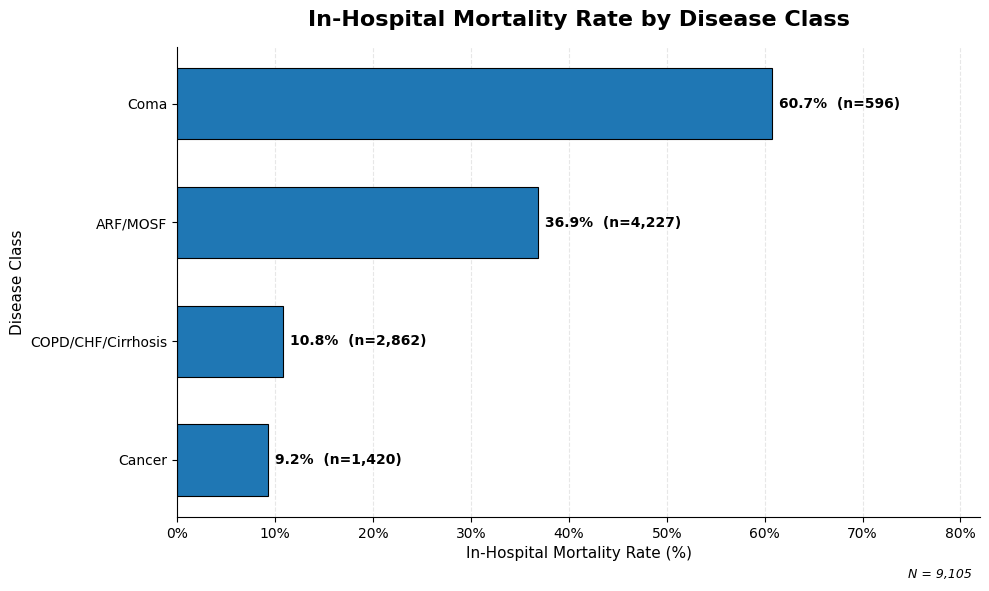

In [8]:
# Calculate mortality rate and sample size by disease class
disease_mortality = (
    df.groupby("dzclass", observed=True)
      .agg(
          mortality_rate=("hospdead", "mean"),
          patient_count=("hospdead", "size")).reset_index())

# Convert mortality rate to percentage
disease_mortality["mortality_percent"] = (
    disease_mortality["mortality_rate"] * 100)

# Sort from highest to lowest mortality rate
disease_mortality = disease_mortality.sort_values(
    "mortality_percent",
    ascending=True)

# Create figure
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    disease_mortality["dzclass"],
    disease_mortality["mortality_percent"],
    height=0.6,
    edgecolor="black",
    linewidth=0.8)

# Add mortality percentage and sample size to each bar
for bar, pct, n in zip(
    bars,
    disease_mortality["mortality_percent"],
    disease_mortality["patient_count"]):
    ax.text(
        bar.get_width() + 0.7,
        bar.get_y() + bar.get_height() / 2,
        f"{pct:.1f}%  (n={n:,})",
        va="center",
        fontsize=10,
        fontweight="bold")

# Titles and labels
ax.set_title(
    "In-Hospital Mortality Rate by Disease Class",
    fontsize=16,
    fontweight="bold",
    pad=15)

ax.set_xlabel("In-Hospital Mortality Rate (%)", fontsize=11)
ax.set_ylabel("Disease Class", fontsize=11)

# Format x-axis as percentages
ax.xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"{x:.0f}%"))

# Give labels room
ax.set_xlim(
    0,
    disease_mortality["mortality_percent"].max() * 1.35)

# Clean appearance
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.3)

ax.set_axisbelow(True)

# Add overall sample size
ax.text(
    0.99,
    -0.13,
    f"N = {len(df):,}",
    transform=ax.transAxes,
    ha="right",
    fontsize=9,
    style="italic")

plt.tight_layout()
plt.show()

In-hospital mortality varied substantially across disease classes. Patients in the Coma disease class had the highest observed mortality rate at 60.7%, followed by patients in the ARF/MOSF class at 36.9%. Lower mortality rates were observed among patients classified with COPD/CHF/Cirrhosis (10.8%) and Cancer (9.2%). These descriptive differences suggest that disease class may contain useful information for predicting in-hospital mortality. However, these unadjusted rates do not account for differences in patient characteristics, disease severity, or other clinical factors across disease classes.

#### 4.3 APACHE III Physiology Score by In-Hospital Mortality

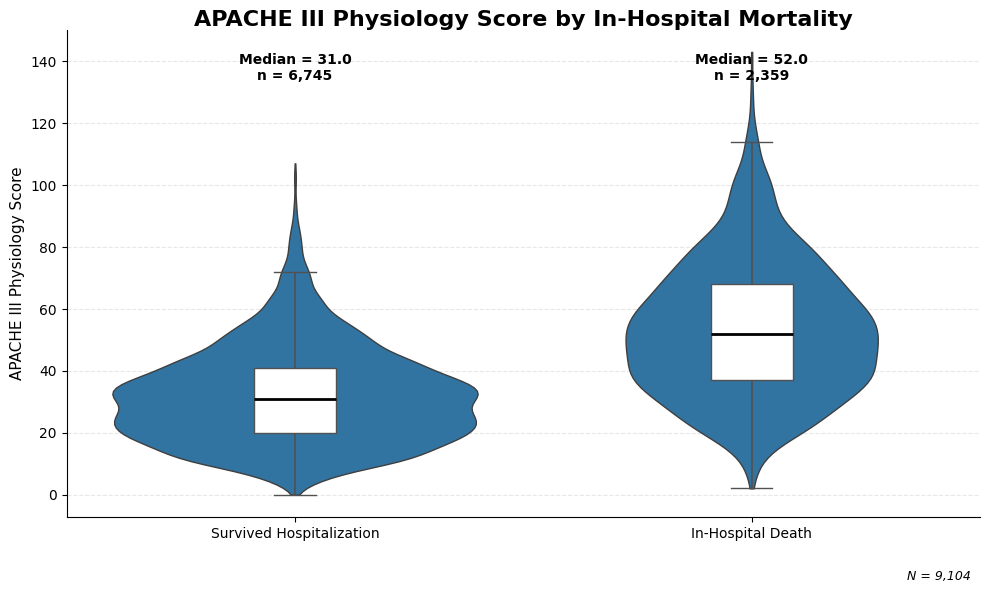

In [9]:
# Prepare data for visualization
aps_plot = df[["aps", "hospdead"]].dropna().copy()

# Replace numeric outcome labels with descriptive labels
aps_plot["Outcome"] = aps_plot["hospdead"].map({
    0: "Survived Hospitalization",
    1: "In-Hospital Death"})

# Create figure
fig, ax = plt.subplots(figsize=(10, 6))

# Violin plot showing the full distribution
sns.violinplot(
    data=aps_plot,
    x="Outcome",
    y="aps",
    inner=None,
    cut=0,
    linewidth=1,
    ax=ax)

# Overlay a compact boxplot
sns.boxplot(
    data=aps_plot,
    x="Outcome",
    y="aps",
    width=0.18,
    showfliers=False,
    boxprops={"facecolor": "white"},
    medianprops={"color": "black", "linewidth": 2},
    whiskerprops={"linewidth": 1.2},
    ax=ax)

# Calculate group medians for annotation
aps_summary = (
    aps_plot.groupby("Outcome")["aps"]
    .agg(["median", "count"])
    .reindex(["Survived Hospitalization", "In-Hospital Death"]))

# Add median and sample-size annotations
for i, (outcome, row) in enumerate(aps_summary.iterrows()):
    ax.text(
        i,
        ax.get_ylim()[1] * 0.95,
        f"Median = {row['median']:.1f}\nn = {int(row['count']):,}",
        ha="center",
        va="top",
        fontsize=10,
        fontweight="bold")

# Titles and labels
ax.set_title(
    "APACHE III Physiology Score by In-Hospital Mortality",
    fontsize=16,
    fontweight="bold",
    pad=1)

ax.set_xlabel("")
ax.set_ylabel("APACHE III Physiology Score", fontsize=11)

# Clean appearance
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.3)

ax.set_axisbelow(True)

# Overall sample-size note
ax.text(
    0.99,
    -0.13,
    f"N = {len(aps_plot):,}",
    transform=ax.transAxes,
    ha="right",
    fontsize=9,
    style="italic")

plt.tight_layout()
plt.show()

Patients who experienced in-hospital mortality had substantially higher APACHE III physiology scores than patients who survived hospitalization. The median score was 52 among patients who died compared with 31 among patients who survived. Although the distributions overlap, the distribution for patients who died is shifted toward higher physiology scores, suggesting that greater physiologic severity may be associated with in-hospital mortality in this sample. One observation with a missing APACHE III score was excluded from this visualization.

## 5. Feature Selection and Leakage Prevention

Predictor eligibility was reviewed before preprocessing to reduce the risk of information leakage. For this analysis, the intended prediction point was defined as SUPPORT study entry, approximately day 3 of hospitalization. The goal is to predict subsequent in-hospital mortality using patient information that could reasonably be available at this time.

Variable metadata were reviewed to assess the clinical meaning and timing of candidate predictors before model development. Particular attention was given to variables that may contain information generated after the intended prediction point or that represent previously generated prognostic assessments.

In [10]:
# Review metadata for candidate predictors before modeling
if DATA_SOURCE == "uci":
    feature_metadata = support2.variables[support2.variables["name"].isin(df.columns)].copy()

    display(feature_metadata[["name", "type", "description"]].reset_index(drop=True))

else:
    print("UCI variable metadata are not displayed for a locally uploaded dataset.")

,name,type,description
0,age,Continuous,Age of the patients in years
1,sex,Categorical,Gender of the patient. Listed values are {male...
2,hospdead,Binary,Death in hospital
3,dzgroup,Categorical,The patient's disease sub category amogst ARF/...
4,dzclass,Categorical,"The patient's disease category amongst ""ARF/MO..."
5,num.co,Continuous,The number of simultaneous diseases (or comorb...
6,edu,Categorical,Years of education
7,income,Categorical,"Income of the patient. Listed values are {""$11..."
8,scoma,Continuous,SUPPORT day 3 Coma Score based on Glasgow scal...
9,charges,Continuous,Hospital charges


### Leakage-Related Feature Exclusion

Based on the metadata review and defined prediction point, several variables were excluded from model development to reduce potential information leakage and prevent existing prognostic assessments from driving model predictions.

Hospital charges and cost variables (`charges`, `totcst`, and `totmcst`) were excluded because they summarize resource utilization that may accumulate beyond the intended prediction point. `avtisst` was excluded because it represents an average TISS score across days 3–25 and therefore incorporates information occurring after study entry.

Existing SUPPORT survival estimates (`surv2m` and `surv6m`) and physician survival estimates (`prg2m` and `prg6m`) were also excluded because they represent previously generated prognostic assessments rather than underlying patient characteristics.

DNR-related variables were also excluded because of their temporal relationship with the prediction point. `dnrday` records the timing of a DNR order and may therefore contain information occurring after study entry. Initial model interpretation also identified DNR status (`dnr`) as disproportionately influential, prompting additional review of the variable's categories. The variable distinguishes among patients with no DNR order, a DNR order before study admission, and a DNR order after study admission. Because the "DNR after study admission" category explicitly incorporates information occurring after the intended prediction point, `dnr` was excluded from the final predictive feature set to maintain temporal consistency and reduce the risk of information leakage.

Day-3 physiologic and laboratory measurements were retained because they correspond to the defined prediction point and represent clinical information available for mortality risk estimation.

In [11]:
# Variables excluded because of potential information leakage
leakage_features = [
    "charges",
    "totcst",
    "totmcst",
    "avtisst",
    "surv2m",
    "surv6m",
    "prg2m",
    "prg6m",
    "dnrday",
    "dnr"]

# Create modeling dataframe
model_df = df.drop(columns=leakage_features).copy()

print("Original predictors:", df.shape[1] - 1)
print("Excluded predictors:", len(leakage_features))
print("Remaining predictors:", model_df.shape[1] - 1)

print("\nExcluded variables:")
for feature in leakage_features:
    print(f"- {feature}")

print("\nModeling dataset shape:", model_df.shape)

Original predictors: 42
Excluded predictors: 10
Remaining predictors: 32

Excluded variables:
- charges
- totcst
- totmcst
- avtisst
- surv2m
- surv6m
- prg2m
- prg6m
- dnrday
- dnr

Modeling dataset shape: (9105, 33)


## 6. Missing Data Assessment

Missingness was reassessed after leakage-related variables were removed so that preprocessing decisions reflect only predictors eligible for model development. Variables were grouped according to the proportion of missing observations to support a structured preprocessing strategy rather than applying identical imputation to every predictor.

In [12]:
# Calculate missingness among modeling predictors
model_predictors = model_df.drop(columns=TARGET)

missing_summary_model = pd.DataFrame({"Missing Count": model_predictors.isna().sum(),
                                      "Missing Percent": model_predictors.isna().mean() * 100})

missing_summary_model = (missing_summary_model[missing_summary_model["Missing Count"] > 0]
                         .sort_values("Missing Percent", ascending=False))

display(missing_summary_model.round(2))

,Missing Count,Missing Percent
adlp,5641,61.95
urine,4862,53.40
glucose,4500,49.42
bun,4352,47.80
alb,3372,37.03
income,2982,32.75
adls,2867,31.49
bili,2601,28.57
pafi,2325,25.54
ph,2284,25.09


### High-Missingness Predictor Exclusion

Predictors with more than 40% missing observations were excluded from the primary modeling dataset. At this level of missingness, imputation would require estimating nearly half or more of the observed values and could introduce substantial uncertainty into the analysis.

This threshold resulted in the exclusion of `adlp`, `urine`, `glucose`, and `bun`. Variables below this threshold were retained and will be handled through the preprocessing pipeline. This approach balances preservation of potentially useful clinical information with the uncertainty introduced by extensive imputation.

In [13]:
MISSINGNESS_THRESHOLD = 0.40

predictor_missingness = (model_df.drop(columns=TARGET).isna().mean())

high_missing_features = predictor_missingness[predictor_missingness > MISSINGNESS_THRESHOLD].index.tolist()

print("Missingness threshold:", f"{MISSINGNESS_THRESHOLD:.0%}")
print("\nPredictors exceeding threshold:")

for feature in high_missing_features:
    pct = predictor_missingness[feature] * 100
    print(f"- {feature}: {pct:.2f}%")

# Remove highly sparse predictors
model_df = model_df.drop(columns=high_missing_features)

print("\nFinal modeling dataset shape:", model_df.shape)
print("Final number of predictors:", model_df.shape[1] - 1)

Missingness threshold: 40%

Predictors exceeding threshold:
- glucose: 49.42%
- bun: 47.80%
- urine: 53.40%
- adlp: 61.95%

Final modeling dataset shape: (9105, 29)
Final number of predictors: 28


## 7. Predictor Type Definition

Predictors were classified according to their documented clinical and statistical meaning rather than relying exclusively on pandas data types. This distinction is important because several SUPPORT2 variables are numerically encoded despite representing binary or categorical information.

Predictors were separated into numerical and categorical groups so that appropriate preprocessing could be applied within the modeling pipeline. Numerical variables will undergo numerical imputation and scaling when required, while categorical variables will undergo categorical imputation and one-hot encoding.

In [14]:
categorical_features = [
    "sex",
    "dzgroup",
    "dzclass",
    "edu",
    "income",
    "race",
    "diabetes",
    "dementia",
    "ca"]

numerical_features = [col for col in model_df.columns
                      if col not in categorical_features + [TARGET]]

print("Categorical predictors:", len(categorical_features))
print("Numerical predictors:", len(numerical_features))
print("Total predictors:", len(categorical_features) + len(numerical_features))

print("\nCategorical predictors:")
print(categorical_features)

print("\nNumerical predictors:")
print(numerical_features)

# Confirm every modeling predictor has been assigned exactly once
assigned_features = set(categorical_features + numerical_features)
expected_features = set(model_df.columns) - {TARGET}

assert assigned_features == expected_features, \
    "Predictor type assignment does not match the modeling dataset."

assert set(categorical_features).isdisjoint(numerical_features), \
    "A predictor was assigned to both groups."

print("\nPredictor type validation: PASSED")

Categorical predictors: 9
Numerical predictors: 19
Total predictors: 28

Categorical predictors:
['sex', 'dzgroup', 'dzclass', 'edu', 'income', 'race', 'diabetes', 'dementia', 'ca']

Numerical predictors:
['age', 'num.co', 'scoma', 'sps', 'aps', 'hday', 'meanbp', 'wblc', 'hrt', 'resp', 'temp', 'pafi', 'alb', 'bili', 'crea', 'sod', 'ph', 'adls', 'adlsc']

Predictor type validation: PASSED


## 8. Clinical Data Quality Review

### Review of Potentially Unusual Clinical Values

Selected physiologic and laboratory predictors were examined for potentially unusual values before modeling. Minimum and maximum values, as well as counts of zero and negative observations, were reviewed to identify measurements that may represent extreme but clinically plausible values, coding conventions, or invalid observations.

Extreme values were not automatically removed because the SUPPORT2 population consists of seriously ill hospitalized patients. Values identified during this review were therefore evaluated cautiously rather than treated as errors solely on the basis of their magnitude.

In [15]:
clinical_vars = [
    "meanbp",
    "wblc",
    "hrt",
    "resp",
    "temp",
    "pafi",
    "alb",
    "bili",
    "crea",
    "sod",
    "ph"]

quality_check = pd.DataFrame({
    "Minimum": model_df[clinical_vars].min(),
    "Maximum": model_df[clinical_vars].max(),
    "Zero Count": (model_df[clinical_vars] == 0).sum(),
    "Negative Count": (model_df[clinical_vars] < 0).sum(),
    "Missing Count": model_df[clinical_vars].isna().sum()})

display(quality_check.round(3))

,Minimum,Maximum,Zero Count,Negative Count,Missing Count
meanbp,0.000,195.000,51,0,1
wblc,0.000,200.000,10,0,212
hrt,0.000,300.000,83,0,1
resp,0.000,90.000,65,0,1
temp,31.699,41.695,0,0,1
pafi,12.000,890.375,0,0,2325
alb,0.400,29.000,0,0,3372
bili,0.100,63.000,0,0,2601
crea,0.100,21.500,0,0,67
sod,110.000,181.000,0,0,1


### Recoding Physiologically Implausible Zero Values

In [16]:
zero_as_missing = [
    "meanbp",
    "wblc",
    "hrt",
    "resp"]

# Count zeros before recoding
zeros_before = (model_df[zero_as_missing] == 0).sum()

# Recode zero values as missing
model_df[zero_as_missing] = (
    model_df[zero_as_missing]
    .replace(0, np.nan))

# Verify recoding
zero_recode_summary = pd.DataFrame({
    "Zeros Recoded": zeros_before,
    "Remaining Zeros": (model_df[zero_as_missing] == 0).sum(),
    "Missing After Recoding": model_df[zero_as_missing].isna().sum()})

display(zero_recode_summary)

,Zeros Recoded,Remaining Zeros,Missing After Recoding
meanbp,51,0,52
wblc,10,0,222
hrt,83,0,84
resp,65,0,66


### Data Quality Decision

The clinical value review identified zero values for mean arterial blood pressure, white blood cell count, heart rate, and respiratory rate. Because zero values for these measurements are physiologically implausible or unlikely to represent meaningful clinical measurements at the study assessment point, these observations were recoded as missing values rather than retained as valid measurements.

The preprocessing pipeline will subsequently handle these observations using the same missing-data strategy applied to other numerical predictors: median imputation with missingness indicators. This approach avoids assigning arbitrary replacement values while preserving information that the original measurement was unavailable or potentially invalid.

Other extreme physiologic and laboratory values were retained. SUPPORT2 includes seriously ill hospitalized patients, so unusually high or low measurements may represent genuine clinical severity. Extreme observations were therefore not removed solely on the basis of magnitude without evidence that they represented data-entry or coding errors.

## 9. Correlation Analysis

### Correlation Among Numerical Clinical Predictors

Spearman's rank correlation was used to examine relationships among the numerical predictors. Spearman correlation was selected because several clinical variables contain skewed distributions and extreme values, and relationships among physiologic measures may not be strictly linear. Unlike Pearson correlation, Spearman correlation evaluates monotonic relationships using ranked observations and is less sensitive to extreme values.

The mortality outcome was excluded from the correlation matrix because the purpose of this analysis is to examine relationships among predictor variables. Associations between predictors and in-hospital mortality are evaluated separately through inferential analysis and predictive modeling.

In [17]:
# Calculate Spearman correlations among numerical predictors
corr_matrix = model_df[numerical_features].corr(method="spearman")

display(corr_matrix.round(2))

,age,num.co,scoma,sps,aps,hday,meanbp,wblc,hrt,resp,temp,pafi,alb,bili,crea,sod,ph,adls,adlsc
age,1.00,0.12,0.04,-0.11,0.02,-0.08,-0.04,0.01,-0.15,0.00,-0.08,0.02,0.08,-0.13,0.08,0.03,-0.03,0.13,0.12
num.co,0.12,1.00,-0.12,-0.06,0.03,-0.18,-0.02,-0.05,-0.08,0.02,-0.12,0.07,0.06,0.01,0.07,-0.03,-0.03,0.17,0.15
scoma,0.04,-0.12,1.00,0.25,0.28,0.26,-0.01,0.10,0.08,0.02,0.10,-0.03,-0.10,0.10,0.06,0.06,0.04,0.08,0.13
sps,-0.11,-0.06,0.25,1.00,0.78,0.37,-0.17,0.13,0.24,0.10,0.07,-0.23,-0.28,0.26,0.16,-0.04,-0.03,0.08,0.09
aps,0.02,0.03,0.28,0.78,1.00,0.37,-0.16,0.10,0.19,0.15,0.07,-0.17,-0.23,0.24,0.27,0.01,-0.05,0.08,0.10
hday,-0.08,-0.18,0.26,0.37,0.37,1.00,-0.02,0.09,0.13,0.03,0.13,-0.11,-0.18,0.17,0.08,0.01,0.04,-0.04,-0.02
meanbp,-0.04,-0.02,-0.01,-0.17,-0.16,-0.02,1.00,-0.01,-0.02,0.02,-0.02,0.16,0.14,-0.13,-0.15,0.07,0.09,-0.00,-0.03
wblc,0.01,-0.05,0.10,0.13,0.10,0.09,-0.01,1.00,0.17,0.05,0.12,-0.16,-0.16,0.04,0.08,-0.01,-0.02,-0.02,-0.00
hrt,-0.15,-0.08,0.08,0.24,0.19,0.13,-0.02,0.17,1.00,0.19,0.27,-0.18,-0.25,0.14,-0.02,0.02,-0.03,0.01,0.02
resp,0.00,0.02,0.02,0.10,0.15,0.03,0.02,0.05,0.19,1.00,0.07,-0.08,-0.03,0.03,-0.02,0.03,0.00,0.02,0.02


In [18]:
# Identify strongest pairwise correlations
corr_pairs = (corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
              .stack().reset_index())

corr_pairs.columns = ["Variable 1", "Variable 2", "Spearman Correlation"]

corr_pairs["Absolute Correlation"] = (corr_pairs["Spearman Correlation"].abs())

corr_pairs = corr_pairs.sort_values("Absolute Correlation",ascending=False)

display(corr_pairs.head(10).round(3))

,Variable 1,Variable 2,Spearman Correlation,Absolute Correlation
170,adls,adlsc,1.000,1.000
51,sps,aps,0.784,0.784
52,sps,hday,0.374,0.374
66,aps,hday,0.367,0.367
36,scoma,aps,0.277,0.277
59,sps,alb,-0.275,0.275
117,hrt,temp,0.271,0.271
150,alb,bili,-0.268,0.268
75,aps,crea,0.268,0.268
60,sps,bili,0.257,0.257


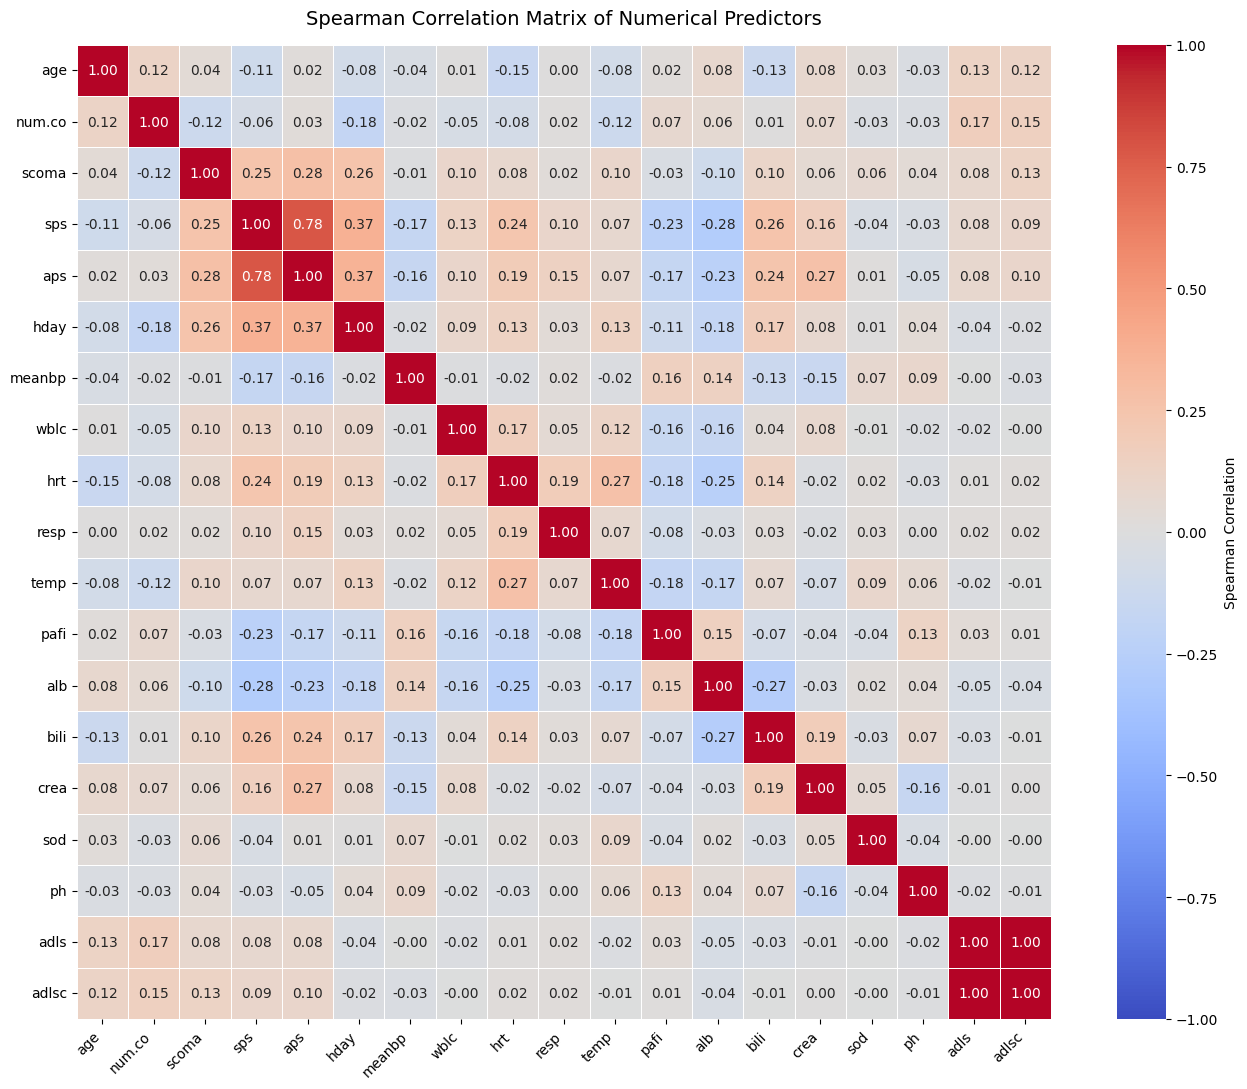

In [19]:
# Visualize Spearman correlations among numerical predictors
plt.figure(figsize=(14, 11))

sns.heatmap(corr_matrix,
            annot=True,
            fmt=".2f",
            vmin=-1,
            vmax=1,
            center=0,
            cmap="coolwarm",
            square=True,
            linewidths=0.5,
            cbar_kws={"label": "Spearman Correlation"})

plt.title("Spearman Correlation Matrix of Numerical Predictors",
          fontsize=14,
          pad=15)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

#### Correlation Analysis Results

Most numerical predictors demonstrated weak pairwise correlations, suggesting that many variables capture distinct aspects of patient characteristics and clinical status.

The strongest relationship was between `adls` and `adlsc` ($r_s = 1.000$), indicating essentially perfect agreement between the two Activities of Daily Living measures. Because these variables represent closely related measures of functional status, their near-perfect correlation indicates substantial redundancy. Both were retained in the current predictive comparison, but this redundancy should be considered when interpreting model features and when adapting the pipeline to other datasets.

A strong positive correlation was also observed between the SUPPORT physiology score (`sps`) and APACHE III physiology score (`aps`) ($r_s = 0.784$). This relationship is clinically and analytically plausible because both variables summarize aspects of physiologic illness severity.

The next strongest relationships were considerably smaller. `sps` and hospital study day (`hday`) had a positive correlation of $r_s = 0.374$, while `aps` and `hday` had a correlation of $r_s = 0.367$. Other relationships had absolute correlations below approximately 0.30, including the associations between `scoma` and `aps` ($r_s = 0.277$), `sps` and albumin ($r_s = -0.275$), and albumin and bilirubin ($r_s = -0.268$).

Overall, with the exception of the highly related ADL measures and the two physiology severity scores, the numerical predictors did not demonstrate extensive pairwise correlation. These relationships describe statistical associations among predictors and should not be interpreted as evidence of causal relationships.

## 10. Train-Test Split

The final modeling dataset was divided into training and testing sets before fitting any learned preprocessing transformations. An 80/20 split was used, with stratification by the `hospdead` outcome to preserve the mortality class distribution in both subsets.

The training set will be used to fit preprocessing transformations and machine learning models, while the test set will remain unseen during model development and will be reserved for final model evaluation. This separation reduces the risk of information leakage and provides a more realistic assessment of performance on unseen observations.

In [20]:
X = model_df.drop(columns=TARGET)
y = model_df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(X,
                                                    y,
                                                    test_size=TEST_SIZE,
                                                    random_state=RANDOM_STATE,
                                                    stratify=y)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).sort_index().round(4))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).sort_index().round(4))

# Confirm no overlap in observations
assert set(X_train.index).isdisjoint(set(X_test.index)), \
    "Training and testing sets contain overlapping observations."

print("\nTrain-test overlap check: PASSED")

Training set shape: (7284, 28)
Testing set shape: (1821, 28)

Training target distribution:
hospdead
0    0.7408
1    0.2592
Name: proportion, dtype: float64

Testing target distribution:
hospdead
0    0.7408
1    0.2592
Name: proportion, dtype: float64

Train-test overlap check: PASSED


## 11. Preprocessing Pipeline

Preprocessing was implemented using a scikit-learn `ColumnTransformer` so that numerical and categorical predictors could be handled appropriately within a reproducible modeling workflow.

For numerical predictors, missing observations are imputed using the median of the training data. Missingness indicators are also generated for numerical predictors containing missing values so that the models can retain information about whether a measurement was originally unavailable. Median imputation was selected because it is relatively robust to extreme clinical values.

Numerical predictors are subsequently standardized to support scale-sensitive models. Categorical predictors use an explicit `Missing` category for unavailable observations and are then one-hot encoded. Unknown categories encountered in new data are ignored rather than causing the pipeline to fail.

All learned preprocessing parameters are estimated from the training data when the preprocessing pipeline is fit as part of a machine learning pipeline. The test set therefore does not contribute information to imputation values, scaling parameters, or categorical encoding.

In [21]:
from sklearn.preprocessing import FunctionTransformer

In [22]:
# Numerical preprocessing
numeric_transformer = Pipeline(
    steps=[("imputer", SimpleImputer(strategy="median", add_indicator=True)),
     ("scaler", StandardScaler())])

In [23]:
# Categorical preprocessing
categorical_transformer = Pipeline(
    steps=[("imputer",
            SimpleImputer(strategy="constant",
                          fill_value="Missing")),
                           ("to_string",
                            FunctionTransformer(lambda X: X.astype(str),
                                                feature_names_out="one-to-one")),
                                                 ("encoder", OneHotEncoder(handle_unknown="ignore"))])


In [24]:
# Combine preprocessing workflows
preprocessor = ColumnTransformer(
    transformers=[("numeric", numeric_transformer, numerical_features),
     ("categorical", categorical_transformer, categorical_features)])

In [25]:
print("Preprocessing pipeline created successfully.")
print(f"Numerical predictors: {len(numerical_features)}")
print(f"Categorical predictors: {len(categorical_features)}")

Preprocessing pipeline created successfully.
Numerical predictors: 19
Categorical predictors: 9


## 12. Inferential Statistical Analysis

Two inferential statistical analyses were conducted to evaluate relationships identified during exploratory analysis. First, APACHE III physiology scores were compared between patients who survived hospitalization and those who experienced in-hospital mortality using a Mann–Whitney U test. Second, the association between disease class and in-hospital mortality was evaluated using a chi-square test of independence. Effect sizes were calculated for both analyses to evaluate the magnitude of the observed relationships in addition to statistical significance.

### APACHE III Physiology Score and In-Hospital Mortality

The first inferential analysis evaluated whether APACHE III physiology scores (`aps`) differed between patients who survived hospitalization and those who experienced in-hospital mortality. This analysis extends the earlier descriptive and visual comparison of physiologic severity between the two outcome groups.

The null hypothesis states that APACHE III physiology scores do not differ between the survival and mortality groups. The alternative hypothesis states that APACHE III physiology scores differ between the groups. Statistical significance was evaluated using an alpha level of 0.05.

A Mann–Whitney U test was selected to compare APS between the two independent mortality groups. This nonparametric approach does not require the assumption of normally distributed APS values and is appropriate for evaluating differences in the distributions of a continuous measure between two independent groups.



#### APS Descriptive Comparison

In [26]:
aps_survived = df.loc[df[TARGET] == 0, "aps"].dropna()
aps_died = df.loc[df[TARGET] == 1, "aps"].dropna()

print("Survived:")
print(f"n = {len(aps_survived):,}")
print(f"Mean APS = {aps_survived.mean():.2f}")
print(f"Median APS = {aps_survived.median():.2f}")
print(f"SD = {aps_survived.std():.2f}")

print("\nIn-hospital mortality:")
print(f"n = {len(aps_died):,}")
print(f"Mean APS = {aps_died.mean():.2f}")
print(f"Median APS = {aps_died.median():.2f}")
print(f"SD = {aps_died.std():.2f}")

Survived:
n = 6,745
Mean APS = 32.00
Median APS = 31.00
SD = 15.68

In-hospital mortality:
n = 2,359
Mean APS = 53.61
Median APS = 52.00
SD = 21.91


### Mann-Whitney U Test

In [27]:
from scipy.stats import mannwhitneyu

# Mann-Whitney U test
u_statistic, p_value = mannwhitneyu(aps_survived,
                                    aps_died,
                                    alternative="two-sided")

print("Mann-Whitney U Test")
print("-" * 40)
print(f"U statistic: {u_statistic:,.0f}")
print(f"P-value: {p_value:.6g}")
print(f"Alpha: 0.05")

if p_value < 0.05:
    print("\nResult: Reject the null hypothesis.")
    print("APS differs significantly between mortality groups.")
else:
    print("\nResult: Fail to reject the null hypothesis.")
    print("There is insufficient evidence of a difference in APS between groups.")

Mann-Whitney U Test
----------------------------------------
U statistic: 3,332,082
P-value: 0
Alpha: 0.05

Result: Reject the null hypothesis.
APS differs significantly between mortality groups.


### Effect Size

In [28]:
n_survived = len(aps_survived)
n_died = len(aps_died)

rank_biserial = 1 - ((2 * u_statistic) / (n_survived * n_died))

print("Effect Size")
print("-" * 40)
print(f"Rank-biserial correlation: {rank_biserial:.3f}")

effect_magnitude = abs(rank_biserial)

if effect_magnitude < 0.10:
    interpretation = "negligible"
elif effect_magnitude < 0.30:
    interpretation = "small"
elif effect_magnitude < 0.50:
    interpretation = "moderate"
else:
    interpretation = "large"

print(f"Effect magnitude: {interpretation}")

Effect Size
----------------------------------------
Rank-biserial correlation: 0.581
Effect magnitude: large


#### APS and Mortality Results

APACHE III physiology scores differed substantially between patients who survived hospitalization and those who experienced in-hospital mortality. Patients who survived had a median APS of 31, compared with a median of 52 among patients who died in the hospital.

A two-sided Mann–Whitney U test identified a statistically significant difference in the distribution of APS between the two mortality groups (U = 3,332,082, p < 0.001). The rank-biserial correlation was 0.581, indicating a large effect size.

These findings suggest that greater physiologic severity, as measured by APACHE III physiology score, is strongly associated with in-hospital mortality in the SUPPORT2 population. Because the data are observational, this relationship should be interpreted as an association rather than evidence that higher APS itself causes mortality.

### Disease Class and In-Hospital Mortality

A second inferential analysis was conducted to evaluate whether disease class was associated with in-hospital mortality. Because both disease class and mortality status are categorical variables, a chi-square test of independence was used.

The null hypothesis states that disease class and in-hospital mortality are independent. The alternative hypothesis states that mortality status is associated with disease class.

The chi-square test statistic is calculated as:

$$
\chi^2 = \sum \frac{(O-E)^2}{E}
$$

where $O$ represents the observed frequency in each contingency-table cell and $E$ represents the expected frequency under the assumption that disease class and mortality are independent.

A significance level of $\alpha = 0.05$ was used. Expected cell frequencies were also evaluated to verify that the assumptions of the chi-square test were appropriate.

#### Chi-Square Test of Independence

In [29]:
from scipy.stats import chi2_contingency

# Create contingency table
disease_mortality_table = pd.crosstab(
    df["dzclass"],
    df[TARGET]
)

print("Disease Class × In-Hospital Mortality")
display(disease_mortality_table)

# Chi-square test of independence
chi2, p_value_chi, dof, expected = chi2_contingency(
    disease_mortality_table
)

print("\nChi-Square Test of Independence")
print("-" * 40)
print(f"Chi-square statistic: {chi2:.3f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p_value_chi:.6g}")

# Check expected-frequency assumption
expected_df = pd.DataFrame(
    expected,
    index=disease_mortality_table.index,
    columns=disease_mortality_table.columns
)

print("\nExpected Frequency Check")
print(f"Minimum expected frequency: {expected_df.min().min():.2f}")
print(
    "Cells with expected frequency < 5:",
    (expected_df < 5).sum().sum()
)

if p_value_chi < 0.05:
    print("\nResult: Reject the null hypothesis.")
    print(
        "Disease class is significantly associated "
        "with in-hospital mortality."
    )
else:
    print("\nResult: Fail to reject the null hypothesis.")
    print(
        "There is insufficient evidence of an association "
        "between disease class and in-hospital mortality."
    )

Disease Class × In-Hospital Mortality


hospdead,0,1
dzclass,,
ARF/MOSF,2668,1559
COPD/CHF/Cirrhosis,2554,308
Cancer,1289,131
Coma,234,362



Chi-Square Test of Independence
----------------------------------------
Chi-square statistic: 1189.418
Degrees of freedom: 3
P-value: 1.44935e-257

Expected Frequency Check
Minimum expected frequency: 154.48
Cells with expected frequency < 5: 0

Result: Reject the null hypothesis.
Disease class is significantly associated with in-hospital mortality.


#### Cramer's V effect size

In [30]:
# Cramer's V effect size
n = disease_mortality_table.to_numpy().sum()

cramers_v = np.sqrt(
    chi2 /
    (
        n * min(
            disease_mortality_table.shape[0] - 1,
            disease_mortality_table.shape[1] - 1
        )
    )
)

print("Effect Size")
print("-" * 40)
print(f"Cramér's V: {cramers_v:.3f}")

Effect Size
----------------------------------------
Cramér's V: 0.361


#### Disease Class and Mortality Results

Disease class was significantly associated with in-hospital mortality in the SUPPORT2 population. A chi-square test of independence identified a statistically significant association between disease class and mortality status, $\chi^2(3) = 1189.42$, $p < 0.001$.

The assumptions of the chi-square test were satisfied. The minimum expected cell frequency was 154.48, and no cells had expected frequencies below 5.

The magnitude of the association was evaluated using Cramér's V, which was 0.361. This indicates a meaningful association between disease class and in-hospital mortality beyond statistical significance alone.

The observed mortality patterns also differed substantially across disease categories. Patients in the Coma and ARF/MOSF groups experienced considerably higher in-hospital mortality than patients in the COPD/CHF/Cirrhosis and Cancer groups. These results are consistent with the earlier exploratory analysis and demonstrate that underlying disease category is associated with mortality risk in this seriously ill hospitalized population.

Because this analysis is observational, the results indicate an association between disease class and mortality and should not be interpreted as evidence that disease class itself causes mortality.

## 13. Reusable Model Evaluation Function

To support consistent comparison across supervised machine learning models, a reusable evaluation function was developed. The function calculates the same set of classification and probability-based performance metrics for each fitted model, reducing duplicated code and ensuring that models are evaluated using a standardized workflow.

Because in-hospital mortality represents approximately 26% of the sample, evaluation extends beyond overall accuracy. Metrics include ROC-AUC, precision-recall AUC, sensitivity, specificity, precision, F1 score, and Brier score. Together, these measures assess discrimination, identification of mortality cases, classification performance, and the quality of predicted probabilities.

In [31]:
def evaluate_model(model, X_test, y_test, model_name):
    """
    Evaluate a fitted binary classification model on the held-out test set.

    Parameters
    ----------
    model : fitted sklearn-compatible model
        Model or pipeline used to generate predictions.

    X_test : pandas DataFrame
        Held-out predictor data.

    y_test : pandas Series
        True binary outcome values.

    model_name : str
        Name used to identify the model in the results table.

    Returns
    -------
    pandas DataFrame
        One-row table containing model performance metrics.
    """

    # Generate class predictions
    y_pred = model.predict(X_test)

    # Generate predicted probabilities for the positive class
    y_prob = model.predict_proba(X_test)[:, 1]

    # Extract confusion matrix values
    tn, fp, fn, tp = confusion_matrix(y_test,
                                      y_pred,
                                      labels=[0, 1]).ravel()

    # Calculate specificity
    specificity = tn / (tn + fp)

    # Store evaluation metrics
    results = pd.DataFrame({"Model": [model_name],
                            "Accuracy": [accuracy_score(y_test, y_pred)],
                            "ROC-AUC": [roc_auc_score(y_test, y_prob)],
                            "PR-AUC": [average_precision_score(y_test, y_prob)],
                            "Sensitivity": [recall_score(y_test, y_pred)],
                            "Specificity": [specificity],
                            "Precision": [precision_score(y_test, y_pred, zero_division=0)],
                            "F1 Score": [f1_score(y_test, y_pred)],
                            "Brier Score": [brier_score_loss(y_test, y_prob)]})

    return results

## 14. Supervised Machine Learning

Multiple supervised classification algorithms were evaluated to predict in-hospital mortality. Each model was incorporated into a scikit-learn pipeline containing the previously defined preprocessing workflow. This structure ensures that imputation, missingness indicators, scaling, and categorical encoding are learned from the training data rather than from the held-out test set.

Model performance will be compared using ROC-AUC as the predefined primary evaluation metric. Because in-hospital mortality represents approximately 26% of observations, additional metrics including precision-recall AUC, sensitivity, specificity, precision, F1 score, accuracy, and Brier score will be considered to provide a more complete assessment of classification performance.

The held-out test set is reserved for final evaluation and is not used to fit model parameters or preprocessing transformations.


### Logistic Regression

Logistic regression was used as an interpretable baseline classification model. It estimates the probability of in-hospital mortality as a function of the available patient characteristics and provides a useful reference point for evaluating whether more complex machine learning algorithms improve predictive performance.

The model was fit using the shared preprocessing pipeline. Class weights were balanced to account for the unequal frequencies of survival and in-hospital mortality in the training data.

In [32]:
from sklearn.linear_model import LogisticRegression

In [33]:
# Logistic regression pipeline
logistic_model = Pipeline(
    steps=[("preprocessor", preprocessor),
     ("classifier", LogisticRegression(class_weight="balanced",
                                       max_iter=2000,
                                       random_state=RANDOM_STATE))])

# Fit using training data only
logistic_model.fit(X_train, y_train)

print("Logistic regression model fitted successfully.")

Logistic regression model fitted successfully.


In [34]:
logistic_results = evaluate_model(logistic_model,
                                  X_test,
                                  y_test,
                                  "Logistic Regression")

display(logistic_results.round(3))

,Model,Accuracy,ROC-AUC,PR-AUC,Sensitivity,Specificity,Precision,F1 Score,Brier Score
0,Logistic Regression,0.778,0.86,0.711,0.763,0.784,0.552,0.641,0.152


In [35]:
model_results = [logistic_results]

### Support Vector Machine

A support vector machine (SVM) classifier was evaluated as a nonlinear alternative to logistic regression. SVMs identify a decision boundary that maximizes separation between outcome classes and can model more complex relationships through kernel functions.

A radial basis function (RBF) kernel was used to allow nonlinear relationships between predictors and in-hospital mortality. Balanced class weights were applied to account for the unequal frequencies of survival and mortality. Probability estimation was enabled so that ROC-AUC, precision-recall AUC, and Brier score could be calculated consistently with the other models.

In [36]:
from sklearn.svm import SVC

In [37]:
# Support Vector Machine pipeline
svm_model = Pipeline(
    steps=[("preprocessor", preprocessor),("classifier",SVC(kernel="rbf",
                                                            class_weight="balanced",
                                                            probability=True,
                                                            random_state=RANDOM_STATE))])

svm_model.fit(X_train, y_train)

print("Support Vector Machine fitted successfully.")

Support Vector Machine fitted successfully.


In [38]:
svm_results = evaluate_model(svm_model,
                             X_test,
                             y_test,"Support Vector Machine")

display(svm_results.round(3))

,Model,Accuracy,ROC-AUC,PR-AUC,Sensitivity,Specificity,Precision,F1 Score,Brier Score
0,Support Vector Machine,0.772,0.852,0.676,0.754,0.778,0.543,0.631,0.131


In [39]:
model_results.append(svm_results)

### Decision Tree

A decision tree classifier was evaluated as a nonlinear, rule-based approach to predicting in-hospital mortality. Decision trees recursively divide observations according to predictor values, allowing them to capture nonlinear relationships and interactions without requiring a linear relationship between predictors and the outcome.

Balanced class weights were used to account for the unequal frequencies of survival and mortality. The same preprocessing pipeline and held-out test set were used to maintain consistency across model evaluations.

In [40]:
from sklearn.tree import DecisionTreeClassifier

In [41]:
# Decision Tree pipeline
decision_tree_model = Pipeline([
    ("preprocessor", preprocessor), ("classifier",
                                     DecisionTreeClassifier(class_weight="balanced",
                                                            random_state=RANDOM_STATE))])

decision_tree_model.fit(X_train, y_train)

print("Decision Tree fitted successfully.")

Decision Tree fitted successfully.


In [42]:
decision_tree_results = evaluate_model(decision_tree_model,
                                       X_test,
                                       y_test,
                                       "Decision Tree")

display(decision_tree_results.round(3))

,Model,Accuracy,ROC-AUC,PR-AUC,Sensitivity,Specificity,Precision,F1 Score,Brier Score
0,Decision Tree,0.752,0.681,0.399,0.532,0.83,0.522,0.527,0.248


In [43]:
model_results.append(decision_tree_results)

### Random Forest

A random forest classifier was evaluated as an ensemble-based extension of the decision tree model. Random forests combine predictions from multiple decision trees constructed using bootstrap samples and random subsets of predictors. This approach can capture nonlinear relationships and interactions while reducing the tendency of an individual decision tree to overfit the training data.

Balanced class weights were used to account for the unequal frequencies of survival and in-hospital mortality. The model was evaluated using the same preprocessing pipeline and held-out test set as the previous classifiers.

In [44]:
from sklearn.ensemble import RandomForestClassifier

In [45]:
# Random Forest pipeline
random_forest_model = Pipeline([
    ("preprocessor", preprocessor),("classifier",
                                    RandomForestClassifier(n_estimators=300,
                                                           class_weight="balanced",
                                                           random_state=RANDOM_STATE,
                                                           n_jobs=1))])

random_forest_model.fit(X_train, y_train)

print("Random Forest fitted successfully.")

Random Forest fitted successfully.


In [46]:
random_forest_results = evaluate_model(random_forest_model,
                                       X_test,
                                       y_test,
                                       "Random Forest")

display(random_forest_results.round(3))

,Model,Accuracy,ROC-AUC,PR-AUC,Sensitivity,Specificity,Precision,F1 Score,Brier Score
0,Random Forest,0.823,0.858,0.712,0.477,0.944,0.748,0.582,0.127


In [47]:
model_results.append(random_forest_results)

### Bagging Classifier

A bagging classifier was evaluated as an ensemble method designed to improve the stability and generalizability of individual decision trees. Bagging fits multiple base estimators using bootstrap samples of the training data and combines their predictions, reducing the variance associated with a single decision tree.

A decision tree was used as the base estimator. The same preprocessing pipeline and held-out test set were used to maintain consistency across model evaluations.

In [48]:
from sklearn.ensemble import BaggingClassifier

In [49]:
# Bagging pipeline
bagging_model = Pipeline([
    ("preprocessor", preprocessor), ("classifier",
                                     BaggingClassifier(
                                         estimator=DecisionTreeClassifier(class_weight="balanced",
                                                                          random_state=RANDOM_STATE),
                                         n_estimators=100,
                                         random_state=RANDOM_STATE,
                                         n_jobs=1))])

bagging_model.fit(X_train, y_train)

print("Bagging Classifier fitted successfully.")

Bagging Classifier fitted successfully.


In [50]:
bagging_results = evaluate_model(bagging_model,
                                 X_test,
                                 y_test,
                                 "Bagging Classifier")

display(bagging_results.round(3))

,Model,Accuracy,ROC-AUC,PR-AUC,Sensitivity,Specificity,Precision,F1 Score,Brier Score
0,Bagging Classifier,0.808,0.852,0.692,0.489,0.92,0.681,0.57,0.129


In [51]:
model_results.append(bagging_results)

### AdaBoost Classifier

An AdaBoost classifier was evaluated as a boosting-based ensemble method. Unlike bagging methods that train estimators independently, AdaBoost sequentially fits weak learners while placing greater emphasis on observations that were incorrectly classified by earlier learners. The resulting predictions are combined to produce the final classification.

The same preprocessing pipeline and held-out test set were used to maintain a consistent evaluation framework across models.

In [52]:
from sklearn.ensemble import AdaBoostClassifier

In [53]:
# AdaBoost pipeline
adaboost_model = Pipeline([
    ("preprocessor", preprocessor), ("classifier",
                                     AdaBoostClassifier(n_estimators=100,
                                                        learning_rate=1.0,
                                                        random_state=RANDOM_STATE))])

adaboost_model.fit(X_train, y_train)

print("AdaBoost Classifier fitted successfully.")

AdaBoost Classifier fitted successfully.


In [54]:
adaboost_results = evaluate_model(adaboost_model,
                                  X_test,
                                  y_test,
                                  "AdaBoost")

display(adaboost_results.round(3))

,Model,Accuracy,ROC-AUC,PR-AUC,Sensitivity,Specificity,Precision,F1 Score,Brier Score
0,AdaBoost,0.817,0.852,0.694,0.521,0.92,0.695,0.596,0.179


In [55]:
model_results.append(adaboost_results)

### Gradient Boosting Classifier

A gradient boosting classifier was evaluated as an additional boosting-based ensemble method. Gradient boosting builds decision trees sequentially, with each new tree attempting to reduce the prediction errors produced by the existing ensemble. This approach can capture nonlinear relationships and interactions while progressively improving predictive performance.

The same preprocessing pipeline and held-out test set were used to maintain consistency across model evaluations.

In [56]:
from sklearn.ensemble import GradientBoostingClassifier

In [57]:
# Gradient Boosting pipeline
gradient_boosting_model = Pipeline([
    ("preprocessor", preprocessor), ("classifier",
                                     GradientBoostingClassifier(n_estimators=100,
                                                                learning_rate=0.1,
                                                                random_state=RANDOM_STATE))])

gradient_boosting_model.fit(X_train, y_train)

print("Gradient Boosting Classifier fitted successfully.")

Gradient Boosting Classifier fitted successfully.


In [58]:
gradient_boosting_results = evaluate_model(gradient_boosting_model,
                                           X_test,
                                           y_test,
                                           "Gradient Boosting")

display(gradient_boosting_results.round(3))

,Model,Accuracy,ROC-AUC,PR-AUC,Sensitivity,Specificity,Precision,F1 Score,Brier Score
0,Gradient Boosting,0.819,0.862,0.715,0.532,0.92,0.699,0.604,0.124


In [59]:
model_results.append(gradient_boosting_results)

### XGBoost Classifier

An XGBoost classifier was evaluated as an optimized gradient boosting approach. XGBoost builds decision trees sequentially, with each new tree attempting to correct errors made by the existing ensemble. Regularization and optimized tree construction are incorporated to improve computational efficiency and reduce overfitting.

The same preprocessing pipeline and held-out test set were used to maintain a consistent evaluation framework across classifiers.

In [60]:
from xgboost import XGBClassifier

In [61]:
# XGBoost pipeline
xgboost_model = Pipeline([
    ("preprocessor", preprocessor), ("classifier",
                                     XGBClassifier(n_estimators=100,
                                                   learning_rate=0.1,
                                                   max_depth=3,
                                                   objective="binary:logistic",
                                                   eval_metric="logloss",
                                                   random_state=RANDOM_STATE,
                                                   n_jobs=1))])

xgboost_model.fit(X_train, y_train)

print("XGBoost Classifier fitted successfully.")

XGBoost Classifier fitted successfully.


In [62]:
xgboost_results = evaluate_model(xgboost_model,
                                 X_test,
                                 y_test,
                                 "XGBoost")

display(xgboost_results.round(3))

,Model,Accuracy,ROC-AUC,PR-AUC,Sensitivity,Specificity,Precision,F1 Score,Brier Score
0,XGBoost,0.824,0.863,0.718,0.528,0.927,0.718,0.608,0.124


In [63]:
model_results.append(xgboost_results)

### Stacking Classifier

A stacking classifier was evaluated to determine whether combining predictions from multiple complementary modeling approaches could improve mortality prediction. Stacking integrates predictions from several base classifiers and uses a final estimator to learn how those predictions should be combined.

Logistic regression, random forest, and gradient boosting were used as base estimators because they represent linear, bagging-based, and boosting-based approaches, respectively. Logistic regression was used as the final estimator. Cross-validation within the stacking procedure was used to generate predictions for training the final estimator while reducing information leakage.

The same preprocessing pipeline and held-out test set were used to maintain consistency with the other model evaluations.

In [64]:
from sklearn.ensemble import StackingClassifier

In [65]:
stacking_classifier = StackingClassifier(
    estimators=[
        ("logistic", LogisticRegression(class_weight="balanced",
                                        max_iter=2000,
                                        random_state=RANDOM_STATE)),
        ("random_forest", RandomForestClassifier(n_estimators=300,
                                                  class_weight="balanced",
                                                  random_state=RANDOM_STATE,
                                                  n_jobs=1)),
        ("gradient_boosting", GradientBoostingClassifier(n_estimators=100,
                                                          learning_rate=0.1,
                                                          random_state=RANDOM_STATE))],
    final_estimator=LogisticRegression(max_iter=2000,
                                       random_state=RANDOM_STATE),
    cv=5,
    stack_method="predict_proba",
    n_jobs=1)

In [66]:
stacking_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", stacking_classifier)])

stacking_model.fit(X_train, y_train)

print("Stacking Classifier fitted successfully.")

Stacking Classifier fitted successfully.


In [67]:
stacking_results = evaluate_model(stacking_model,
                                  X_test,
                                  y_test,
                                  "Stacking")

display(stacking_results.round(3))

,Model,Accuracy,ROC-AUC,PR-AUC,Sensitivity,Specificity,Precision,F1 Score,Brier Score
0,Stacking,0.822,0.865,0.726,0.551,0.916,0.697,0.615,0.124


In [68]:
model_results.append(stacking_results)

### Multilayer Perceptron Neural Network

A multilayer perceptron (MLP) classifier was evaluated as a neural-network-based approach to mortality prediction. Unlike tree-based models, an MLP learns nonlinear relationships through interconnected layers of weighted nodes and nonlinear activation functions.

The model used two hidden layers and early stopping to reduce the risk of unnecessary training and overfitting. The same preprocessing pipeline and held-out test set were used to maintain consistency across model evaluations.

In [69]:
from sklearn.neural_network import MLPClassifier

In [70]:
# MLP pipeline
mlp_model = Pipeline([
    ("preprocessor", preprocessor), ("classifier",
                                     MLPClassifier(hidden_layer_sizes=(64, 32),
                                                   activation="relu",
                                                   solver="adam",
                                                   max_iter=500,
                                                   early_stopping=True,
                                                   random_state=RANDOM_STATE))])

mlp_model.fit(X_train, y_train)

print("MLP Classifier fitted successfully.")

MLP Classifier fitted successfully.


In [71]:
mlp_results = evaluate_model(mlp_model,
                             X_test,
                             y_test,
                             "MLP Neural Network")

display(mlp_results.round(3))

,Model,Accuracy,ROC-AUC,PR-AUC,Sensitivity,Specificity,Precision,F1 Score,Brier Score
0,MLP Neural Network,0.817,0.858,0.712,0.53,0.918,0.693,0.6,0.126


In [72]:
model_results.append(mlp_results)

### Understanding the Evaluation Metrics

Several complementary metrics were used because no single measure fully describes classification performance.

- **Accuracy:** The proportion of all predictions that were classified correctly. Because one outcome may be more common than another, accuracy should not be interpreted alone.

- **Sensitivity (Recall):** The proportion of patients who died in the hospital that the model correctly identified as mortality cases. Higher sensitivity means fewer mortality cases were missed.

- **Specificity:** The proportion of patients who survived that the model correctly identified as survivors. Higher specificity means fewer survivors were incorrectly classified as mortality cases.

- **Precision:** Among patients predicted to experience in-hospital mortality, the proportion who actually died in the hospital.

- **F1 Score:** A combined measure of precision and sensitivity. Higher values indicate a better balance between identifying mortality cases and limiting false-positive predictions.

- **ROC-AUC:** Measures how well the model distinguishes between patients who survived and patients who died across possible classification thresholds. A value of 0.50 represents discrimination similar to random classification, while values closer to 1.00 indicate better discrimination.

- **PR-AUC:** Summarizes the relationship between precision and recall across classification thresholds. This metric is particularly useful when the positive outcome is less common, as in this dataset where approximately 26% of patients experienced in-hospital mortality.

- **Brier Score:** Measures the accuracy of predicted probabilities rather than only whether the final classification was correct. Lower values indicate better probability predictions, with 0 representing perfect predictions.

The Brier score for a binary outcome is calculated as:

$$
\text{Brier Score} = \frac{1}{N}\sum_{i=1}^{N}(p_i-y_i)^2
$$

where $p_i$ is the predicted probability of in-hospital mortality for patient $i$, $y_i$ is the observed outcome (0 or 1), and $N$ is the number of patients evaluated. Unlike metrics where higher values indicate better performance, **lower Brier scores indicate better probabilistic predictions**.

## 15. Model Evaluation and Comparison

Following evaluation of all ten supervised classification models, model performance was compared using a consistent set of metrics calculated on the held-out test set. ROC-AUC was predefined as the primary model-selection metric because it evaluates discrimination across classification thresholds and is less dependent on a single decision threshold than accuracy alone.

PR-AUC, sensitivity, specificity, precision, F1 score, accuracy, and Brier score were also considered to provide a more complete assessment of predictive performance, particularly given the class imbalance in the mortality outcome. Models were ranked using their unrounded ROC-AUC values to avoid selecting a model based on differences obscured by rounded results.

In [73]:
results_df = (pd.concat(model_results, ignore_index=True)
              .drop_duplicates(subset="Model", keep="last")
              .sort_values("ROC-AUC", ascending=False)
              .reset_index(drop=True))

display(results_df)

,Model,Accuracy,ROC-AUC,PR-AUC,Sensitivity,Specificity,Precision,F1 Score,Brier Score
0,Stacking,0.821527,0.864598,0.725925,0.550847,0.916234,0.697051,0.615385,0.124379
1,XGBoost,0.823723,0.862784,0.718019,0.527542,0.927354,0.717579,0.608059,0.124051
2,Gradient Boosting,0.819330,0.862445,0.714863,0.531780,0.919941,0.699164,0.604091,0.124340
3,Logistic Regression,0.778144,0.860490,0.710840,0.762712,0.783543,0.552147,0.640569,0.151632
4,MLP Neural Network,0.817133,0.858208,0.711612,0.529661,0.917717,0.692521,0.600240,0.125632
5,Random Forest,0.822625,0.858177,0.711537,0.476695,0.943662,0.747508,0.582147,0.126841
6,Support Vector Machine,0.771554,0.852469,0.675859,0.754237,0.777613,0.542683,0.631206,0.130633
7,AdaBoost,0.816584,0.852293,0.694169,0.521186,0.919941,0.694915,0.595642,0.178804
8,Bagging Classifier,0.808347,0.851568,0.691751,0.489407,0.919941,0.681416,0.569667,0.129174
9,Decision Tree,0.752334,0.680641,0.398860,0.531780,0.829503,0.521830,0.526758,0.247666


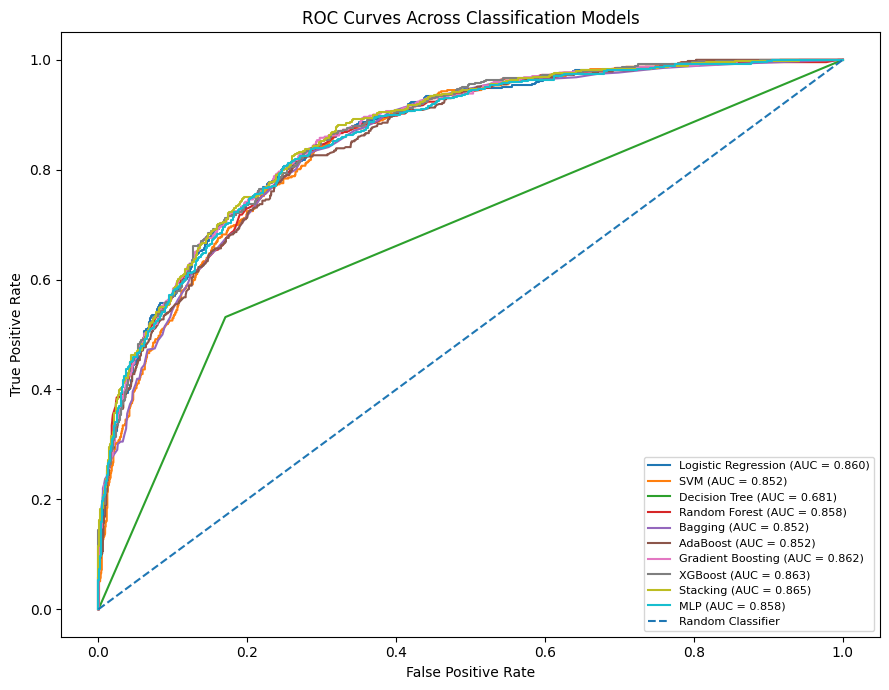

In [74]:
# Plot ROC curves for all classification models
models = {"Logistic Regression": logistic_model,
          "SVM": svm_model,
          "Decision Tree": decision_tree_model,
          "Random Forest": random_forest_model,
          "Bagging": bagging_model,
          "AdaBoost": adaboost_model,
          "Gradient Boosting": gradient_boosting_model,
          "XGBoost": xgboost_model,
          "Stacking": stacking_model,
          "MLP": mlp_model}

plt.figure(figsize=(9, 7))

for name, model in models.items():
    y_prob = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)

    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves Across Classification Models")
plt.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

### Model Performance Visualization

The model comparison demonstrates that several ensemble methods achieved similar discrimination. The stacking classifier produced the highest ROC-AUC and was therefore selected according to the predefined primary evaluation metric. XGBoost and gradient boosting performed similarly, while the single decision tree produced substantially lower discrimination than the other evaluated models.

### 15.1 Model Comparison and Selection

Overall, several models demonstrated good discrimination for in-hospital mortality. The highest-performing models according to the predefined primary metric were the stacking classifier, XGBoost, and gradient boosting, with ROC-AUC values of 0.865, 0.863, and 0.862, respectively.

Based on the predefined model-selection criterion, the stacking classifier achieved the highest ROC-AUC (0.865) and was therefore selected as the final model. Stacking also achieved the highest PR-AUC (0.726) among the evaluated models, indicating comparatively strong discrimination of mortality cases in the presence of class imbalance.

At the default classification threshold, the stacking model achieved an accuracy of 0.822, sensitivity of 0.551, specificity of 0.916, precision of 0.697, and F1 score of 0.615. These results indicate that the model classified survivors with relatively high specificity but identified only approximately 55% of patients who experienced in-hospital mortality. Therefore, although the model demonstrated good overall discrimination across thresholds, its default classification threshold favored specificity over sensitivity.

Logistic regression demonstrated a different performance tradeoff. Although its ROC-AUC (0.860) was slightly lower than that of stacking, logistic regression achieved substantially higher sensitivity (0.763) while producing lower specificity (0.784). This finding illustrates that model selection and classification threshold should depend on the intended clinical use. In a mortality-risk setting where failing to identify a high-risk patient may carry greater consequences than generating a false-positive alert, sensitivity may warrant greater emphasis than overall accuracy or specificity alone.

The stacking classifier had a Brier score of 0.124, while XGBoost and gradient boosting produced similar Brier scores of 0.124 and 0.124, respectively. These results suggest similar overall probability accuracy among the leading ensemble models.

Because ROC-AUC was specified as the primary selection metric before model comparison, the stacking classifier was retained as the final model rather than selecting a model retrospectively based on whichever secondary metric produced the most favorable result.

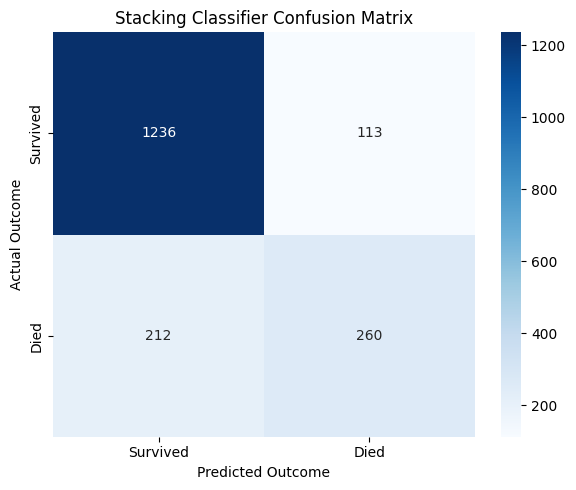

In [75]:
# Confusion matrix for the selected stacking model
stacking_predictions = stacking_model.predict(X_test)

cm = confusion_matrix(y_test, stacking_predictions)

plt.figure(figsize=(6, 5))
sns.heatmap(cm,
            annot=True,
            fmt="d",
            cmap="Blues",
            xticklabels=["Survived", "Died"],
            yticklabels=["Survived", "Died"])

plt.xlabel("Predicted Outcome")
plt.ylabel("Actual Outcome")
plt.title("Stacking Classifier Confusion Matrix")

plt.tight_layout()
plt.show()

### 15.2 Impact of Leakage Review

An initial version of the predictive pipeline retained DNR status (`dnr`) and produced substantially higher model performance. During model interpretation, permutation importance identified DNR status as disproportionately influential relative to the remaining predictors. Further review showed that the variable included a category indicating DNR orders occurring after study admission, meaning that information unavailable at the intended prediction point could contribute to model predictions.

DNR status was therefore excluded from the final feature set, and the complete modeling pipeline was rerun. Following this exclusion, the selected stacking model achieved a ROC-AUC of 0.865, compared with approximately 0.923 in the preliminary analysis that included DNR status. The reduction in performance illustrates the potential effect of temporal information leakage on apparent predictive accuracy. The lower performance of the final model represents a more appropriate estimate of discrimination using predictors aligned with the defined prediction point.

In [76]:
from sklearn.inspection import permutation_importance

# Calculate permutation importance for the final stacking model
stacking_importance = permutation_importance(stacking_model,
                                              X_test,
                                              y_test,
                                              scoring="roc_auc",
                                              n_repeats=10,
                                              random_state=RANDOM_STATE,
                                              n_jobs=1)

importance_df = pd.DataFrame({"Predictor": X_test.columns,
                              "Mean Importance": stacking_importance.importances_mean,
                              "Importance SD": stacking_importance.importances_std})

importance_df = (importance_df
                 .sort_values("Mean Importance", ascending=False)
                 .reset_index(drop=True))

display(importance_df.head(15).round(4))

,Predictor,Mean Importance,Importance SD
0,sps,0.0514,0.0052
1,aps,0.0385,0.0045
2,scoma,0.0246,0.0031
3,adlsc,0.0124,0.0020
4,age,0.0105,0.0017
5,hday,0.0083,0.0006
6,dzgroup,0.0041,0.0015
7,adls,0.0020,0.0014
8,dzclass,0.0016,0.0020
9,wblc,0.0010,0.0004


## 16. Model Interpretation

Permutation importance was used to evaluate the contribution of individual predictors to the final stacking classifier. Because the stacking model combines multiple base learners, it does not provide a single set of conventional coefficients or feature importance values that directly represent the contribution of the original predictors.

Permutation importance provides a model-agnostic approach by measuring the decrease in predictive performance after the values of an individual predictor are randomly shuffled while the remaining predictors are unchanged. Importance was evaluated using ROC-AUC to remain consistent with the predefined primary model-selection metric.

### 16.1 Permutation Importance Results

Permutation importance identified the SUPPORT physiology score (`sps`) as the most influential predictor in the final stacking classifier. Permuting `sps` decreased ROC-AUC by an average of 0.051, indicating that the model relied substantially on information contained in this measure for discrimination between patients who survived hospitalization and those who experienced in-hospital mortality.

The APACHE III physiology score (`aps`) was the second most influential predictor, with a mean ROC-AUC decrease of 0.039, followed by coma score (`scoma`) with a decrease of 0.025. Together, the prominence of these variables indicates that measures of physiologic and neurologic illness severity contributed substantially to the final model's predictive performance.

Functional status also contributed to prediction. The calibrated Activities of Daily Living measure (`adlsc`) produced a mean ROC-AUC decrease of 0.012, while age and hospital study day (`hday`) produced decreases of 0.011 and 0.008, respectively. Disease group (`dzgroup`) provided additional predictive information, although its importance was smaller than that of the primary severity measures.

Most remaining predictors produced relatively small changes in ROC-AUC when permuted. These values should not be interpreted as evidence that the corresponding clinical characteristics are unrelated to mortality. Permutation importance measures the contribution of a predictor in the context of all other predictors available to the model, and importance may be distributed across variables containing overlapping information.

This consideration is particularly relevant for the SUPPORT physiology score (`sps`) and APACHE III physiology score (`aps`), which demonstrated a Spearman correlation of 0.784, and for the two Activities of Daily Living measures (`adls` and `adlsc`), which were nearly perfectly correlated in the exploratory analysis. Consequently, the importance assigned to an individual correlated predictor may underestimate the predictive information represented collectively by related measures.

Overall, the final model interpretation suggests that discrimination of in-hospital mortality was driven primarily by measures of physiologic severity, neurologic status, functional status, age, and timing of study entry. Permutation importance reflects predictive contribution rather than causality and should not be interpreted as demonstrating that these characteristics directly cause in-hospital mortality.

### 16.2 Interpretation as a Model Validation Tool

Model interpretation was also used as a diagnostic component of the analytical workflow rather than solely as a description of the final model. In the preliminary model, DNR status (`dnr`) had substantially greater permutation importance than all other predictors. Examination of the variable revealed that one category represented DNR orders occurring after study admission, creating the possibility of temporal information leakage.

The variable was subsequently excluded, and the complete predictive pipeline was rerun. In the final leakage-reduced model, the most influential predictors were measures of physiologic severity, neurologic status, functional status, age, and hospital study day. The change in both model performance and predictor importance demonstrates the value of interpretability methods for identifying potentially problematic predictors and evaluating whether model behavior is consistent with the intended prediction framework.

## 17. Results and Discussion

This analysis evaluated whether clinical and demographic information available around SUPPORT study entry could be used to predict in-hospital mortality among seriously ill hospitalized patients. The results demonstrate that mortality was associated with substantial differences in clinical severity and disease characteristics and that supervised machine learning models were able to achieve meaningful discrimination after predictors with potential temporal information leakage were excluded.

The inferential analyses identified significant relationships between clinical severity, disease class, and in-hospital mortality. Patients who died during hospitalization had substantially higher APACHE III physiology scores than patients who survived. Median APS was 52 among patients who died compared with 31 among survivors, and the Mann–Whitney U test identified a statistically significant difference in the APS distributions ($p < .001$). The rank-biserial correlation of 0.581 indicated a large effect, supporting the clinical relevance of the observed difference in physiologic severity.

Disease class was also significantly associated with in-hospital mortality ($\chi^2 = 1189.42$, $df = 3$, $p < .001$), with a Cramer's V of 0.361 indicating a meaningful association between disease classification and mortality outcome. Mortality rates varied substantially across disease classes. Patients in the Coma group had the highest observed mortality rate at approximately 60.7%, followed by patients with ARF/MOSF at approximately 36.9%. Mortality was considerably lower among patients classified with COPD/CHF/Cirrhosis and Cancer. These findings demonstrate that mortality risk differed across major diagnostic groups within the SUPPORT2 population.

Predictive modeling further demonstrated that information available near the defined prediction point contained substantial information about in-hospital mortality. Among the ten supervised classification algorithms evaluated, the stacking classifier achieved the highest ROC-AUC (0.865) and was selected as the final model according to the predefined primary selection metric. Stacking also achieved the highest PR-AUC (0.726), with an accuracy of 0.822, sensitivity of 0.551, specificity of 0.916, precision of 0.697, F1 score of 0.615, and Brier score of 0.124.

Although stacking produced the highest overall discrimination, model performance revealed an important classification tradeoff. At the default classification threshold, the model demonstrated high specificity but substantially lower sensitivity, indicating that it was considerably better at correctly identifying survivors than identifying patients who experienced in-hospital mortality. In contrast, logistic regression achieved lower overall discrimination but substantially greater sensitivity (0.763). Therefore, selection of a classification threshold or model for clinical use would require consideration of the relative consequences of false-negative and false-positive predictions rather than reliance on ROC-AUC alone.

Model interpretation indicated that the final stacking classifier relied most strongly on measures related to illness severity. The SUPPORT physiology score (`sps`) produced the largest mean decrease in ROC-AUC during permutation importance analysis (0.051), followed by APACHE III physiology score (`aps`, 0.039) and coma score (`scoma`, 0.025). Functional status, age, hospital study day, and disease group also contributed to predictive discrimination. These findings are consistent with the broader analytical results, in which physiologic severity and disease characteristics were strongly associated with mortality.

An important finding emerged during model interpretation. In the preliminary modeling pipeline, DNR status (`dnr`) demonstrated substantially greater permutation importance than all other predictors. Examination of the variable showed that one category represented DNR orders occurring after study admission, meaning that future information could contribute to predictions made at the intended study-entry prediction point. DNR status was therefore removed, and the complete modeling pipeline was rerun. The final stacking ROC-AUC decreased from approximately 0.923 in the preliminary analysis to 0.865 after this exclusion.

This reduction illustrates how temporal information leakage can produce overly optimistic estimates of predictive performance in clinical data. Importantly, the lower final ROC-AUC should not be interpreted as a deterioration of the analytical workflow. Instead, it represents a more defensible estimate of predictive discrimination using information aligned with the intended prediction point. The finding also demonstrates the value of combining metadata review, clinical reasoning, and model interpretation when developing predictive models from longitudinal health data.

Overall, the results support the conclusion that clinical information available around SUPPORT study entry can discriminate between patients with different risks of in-hospital mortality. Measures of physiologic and neurologic severity were particularly influential, while diagnostic group and functional status contributed additional information. However, the moderate sensitivity observed at the default classification threshold and the substantial effect of removing temporally inappropriate information emphasize that predictive performance alone is insufficient for evaluating the potential usefulness of a clinical mortality model.

## 18. Limitations

Several limitations should be considered when interpreting the results of this analysis.

First, the SUPPORT2 dataset represents a historical cohort of seriously ill hospitalized patients. Clinical practice, treatment patterns, documentation, and approaches to serious illness care may have changed since the data were collected. Consequently, relationships observed in this dataset may not fully represent contemporary hospitalized populations.

Second, the analysis was conducted using a single dataset and a single stratified train-test split. Although the held-out evaluation set provides an estimate of model performance on observations not used for model fitting, the final models were not externally validated in an independent patient population. Model performance may therefore differ when applied to patients from other institutions, time periods, or clinical settings.

Third, substantial missingness was present in several predictors. Variables with more than 40% missingness were excluded using a prespecified pragmatic threshold, while remaining numerical missing values were addressed using median imputation with missingness indicators and categorical missing values were represented as an explicit category. Although these approaches preserve observations and allow the modeling pipeline to operate consistently, imputed values may not fully represent the underlying clinical measurements. Missingness itself may also reflect patterns of clinical decision-making or measurement practices.

Fourth, the analysis required decisions regarding the temporal availability of predictors. Variables containing information occurring after the intended prediction point, including DNR-related information, were excluded to reduce temporal information leakage. The substantial reduction in model performance after removing DNR status demonstrates the sensitivity of clinical prediction models to feature timing and reinforces the importance of carefully defining what information would be available when a prediction is made.

Fifth, model selection was based primarily on ROC-AUC, while classification metrics were calculated using the default probability threshold of 0.50. The selected stacking model demonstrated substantially greater specificity than sensitivity at this threshold. Alternative thresholds could produce different tradeoffs between identifying patients at risk of mortality and incorrectly classifying survivors. Threshold selection would therefore need to be aligned with a clearly defined clinical use case and the relative consequences of false-positive and false-negative predictions.

Sixth, permutation importance describes the contribution of predictors to the fitted model but does not establish causal relationships. Correlated predictors may also share predictive information, potentially reducing the apparent importance of individual variables. This is particularly relevant for highly related measures such as the SUPPORT and APACHE III physiology scores and the two Activities of Daily Living measures.

Finally, this analysis focused on technical predictive performance and did not perform a comprehensive assessment of model fairness, subgroup performance, calibration across patient populations, or prospective clinical utility. Demographic characteristics such as age, sex, and race were included as predictors, but their inclusion should not be interpreted as establishing biological or causal relationships with mortality. Before any clinical application, additional evaluation would be necessary to assess generalizability, calibration, subgroup performance, potential bias, and the consequences of using model predictions in patient care.

Accordingly, the final model should be interpreted as a reproducible demonstration of an end-to-end mortality prediction workflow rather than a clinically validated decision-support system.

## 19. Reproducibility and Workflow Enhancements

Reproducibility and usability were incorporated throughout the analytical workflow so that the analysis can be rerun consistently and adapted to compatible datasets.

A fixed random state (`RANDOM_STATE = 101`) was used for stochastic components of the workflow, including the train-test split and applicable machine learning algorithms. The outcome was divided using a stratified train-test split to preserve the observed mortality distribution across the training and evaluation sets.

Data input was designed to support both reproducible retrieval and user-provided data. By default, SUPPORT2 is retrieved directly from the UCI Machine Learning Repository. Alternatively, users may select the local-upload pathway to provide a compatible CSV file. Conditional logic and input validation confirm the selected data source, file type, and presence of the required target variable before analysis proceeds.

Automated dataset validation evaluates the number of observations and predictors, target availability and coding, duplicate observations, predictor missingness, and constant features. Additional assertions verify predictor-type assignments and separation of the training and evaluation sets. These checks are intended to identify structural or data-quality problems before model development.

Data preprocessing was implemented using scikit-learn pipelines and a `ColumnTransformer`. Numerical predictors undergo median imputation with missingness indicators followed by standardization, while categorical predictors undergo missing-value handling, consistent string conversion, and one-hot encoding. Because preprocessing is contained within each model pipeline, transformations are learned from the training data rather than being estimated from the complete dataset before model fitting.

The workflow also includes explicit procedures for missing-data assessment, exclusion of predictors exceeding the prespecified 40% missingness threshold, review of potentially implausible clinical values, and recoding of physiologically implausible zero measurements as missing when appropriate. Feature selection additionally incorporates the defined prediction point to reduce temporal information leakage.

Reusable functions were used for dataset validation and model evaluation, while common preprocessing components were shared across classification algorithms. All ten supervised classification models were evaluated using the same held-out evaluation data and the same collection of performance metrics. ROC-AUC was defined as the primary model-selection metric before model comparison, and the final model was selected programmatically using the unrounded metric values.

Model interpretation was incorporated as an additional validation step. Identification of unexpectedly high importance for DNR status prompted review of the feature definition, identification of potential temporal leakage, exclusion of the variable, and rerunning of the complete downstream analytical pipeline. This demonstrates how model interpretation can contribute to both understanding model predictions and evaluating the integrity of the analytical workflow.

Finally, the notebook was structured to execute sequentially from data input through validation, preprocessing, statistical analysis, predictive modeling, evaluation, and interpretation. A clean session restart and complete execution of the notebook were used to identify and correct hidden dependencies between cells. Together, these features support a transparent and reproducible workflow that can be reviewed, rerun, and adapted by another analyst.

## 20. Conclusion

This project developed a reproducible end-to-end health data science workflow for predicting in-hospital mortality among seriously ill hospitalized patients in the SUPPORT2 dataset. The analysis integrated automated data validation, clinical data-quality review, missing-data handling, exploratory and inferential statistical analysis, supervised machine learning, model comparison, and model interpretation.

Inferential analyses demonstrated substantial differences in physiologic severity between patients who survived hospitalization and those who died and identified a meaningful association between disease class and in-hospital mortality. Across ten supervised classification algorithms, the stacking classifier achieved the highest predefined primary performance metric, with a final ROC-AUC of 0.865 and PR-AUC of 0.726 after predictors with potential temporal information leakage were excluded.

Permutation importance indicated that the final model relied most strongly on measures of physiologic and neurologic illness severity, particularly the SUPPORT physiology score, APACHE III physiology score, and coma score. Functional status, age, hospital study day, and disease characteristics provided additional predictive information.

A particularly important finding emerged from the model-development process itself. Initial model interpretation identified DNR status as disproportionately influential, and subsequent review demonstrated that the variable contained information occurring after the intended prediction point. Removing this feature reduced apparent model performance but produced a more temporally appropriate and defensible predictive workflow. This finding highlights the importance of evaluating not only how well a clinical model performs, but also whether the information driving its predictions would genuinely be available at the time the prediction is intended to occur.

Overall, the results demonstrate that clinical information available around SUPPORT study entry can provide meaningful discrimination of in-hospital mortality risk. However, the final model remains an analytical demonstration rather than a clinically validated decision-support tool. External validation, further assessment of calibration and subgroup performance, and evaluation of clinically appropriate decision thresholds would be necessary before considering application to contemporary patient care.